In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
import pandas as pd
import numpy as np
import networkx as nx
from collections import defaultdict

import scipy.sparse as spsparse
import scipy.stats as spstats

from sklearn.preprocessing import normalize

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

import pyscisci.all as pyscisci

import scienceplots
plt.style.use('science')


/Users/psp2nq/Documents/NationalBiasCode/.venv/lib/python3.11/site-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


In [2]:
# set this path to where the OpenAlex database is stored (only for the null models, cells 3 and 5)
path2openalex = '/Users/hgt6rn/Documents/DataSets/OpenAlex'

# set this path to where the Source Data is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)


# Create the random countries null model

In [ ]:
from pyscisci.datasource.OpenAlex import OpenAlex

myoa = OpenAlex(path2database=path2openalex, database_extension='csv.gz')


pub2doctype = pd.read_csv(os.path.join(path2openalex, 'pub2doctype.csv.gz'))
pub2year = pd.read_csv(os.path.join(path2openalex, 'pub2year.csv.gz'))

pub2doctype = pub2doctype[pub2doctype['DocType']=='article']
pub2doctype = pub2doctype.merge(pub2year, how='inner', on='PublicationId')
pub2doctype.dropna(inplace=True)

print(pub2doctype['PublicationId'].nunique(), "Articles")
pub2doctype = pub2doctype[np.logical_and(pub2doctype['Year'] >= 1990, pub2doctype['Year'] <= 2023)]
print(pub2doctype['PublicationId'].nunique(), "Articles in timespan")


pub2year = {pid:y for pid, y in pub2doctype[['PublicationId', 'Year']].values}
print(len(pub2year))

pubarticles = np.sort(pub2doctype['PublicationId'].values)
print(pubarticles.shape)

pub2country = pd.read_csv(os.path.join(path2openalex, 'precomputed_data', 'oa_pub2country.csv.gz'))
pub2country['Year'] = [pub2year.get(pid, None) for pid in pub2country['PublicationId'].values]
pub2country['RandomCountry'] = pub2country.groupby('Year', group_keys=False)['Country'].apply(lambda g: g.sample(frac=1)).reset_index(drop=True)

aff_df = myoa.load_affiliations(columns = ['AffiliationId', 'Country'])
aff_df.dropna(inplace=True)
aff_df.reset_index(drop=True, inplace=True)

focus_affs = np.sort(aff_df['AffiliationId'].values)

paa_df = myoa.load_publicationauthoraffiliation(columns=['PublicationId', 'AuthorId', 'AffiliationId'],
                                                filter_dict = {'AffiliationId':focus_affs, 'PublicationId':pubarticles})

paa_df['Year'] = [pub2year.get(pid, None) for pid in paa_df['PublicationId'].values]
paa_df.dropna(inplace=True)

print(paa_df['PublicationId'].nunique(), "Articles in timespan with affiliation information")

print(paa_df.shape)

pub2authors = defaultdict(set)
pub2aff = defaultdict(set)
for pid, aid, aff in paa_df[['PublicationId', 'AuthorId', 'AffiliationId']].values:
    pub2authors[pid].add(aid)
    pub2aff[pid].add(aff)
    
print(len(pub2authors), len(pub2aff))


pub2ref = []

pfiles = os.listdir(os.path.join(path2openalex, 'pub2ref'))
print(len(pfiles))

for ifname in range(len(pfiles)):
    fname = pfiles[ifname]
    if '.csv.gz' in fname:
        df = pd.read_csv(os.path.join(path2openalex, 'pub2ref', fname))
        
        df['CitedYear'] = [pub2year.get(pid, None) for pid in df['CitedPublicationId'].values]
        df.dropna(inplace=True)
        #df = df.loc[df['CitedYear'] <= 2017]
        
        df['CitingYear'] = [pub2year.get(pid, None) for pid in df['CitingPublicationId'].values]
        df.dropna(inplace=True)
        
        df = df.loc[df['CitingYear'] >= df['CitedYear']]
        df = df.loc[df['CitingYear'] <=  df['CitedYear'].values + 5]
        

        noselfciteauthor = np.array([len(pub2authors[citingpid] & pub2authors[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteauthor]
        
        noselfciteaff = np.array([len(pub2aff[citingpid] & pub2aff[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteaff]
        
        pub2ref.append(df[['CitingPublicationId', 'CitingYear', 'CitedPublicationId', 'CitedYear']])
    if ifname % 50 == 0:
        print(ifname)

pub2ref = pd.concat(pub2ref)
pub2ref.drop_duplicates(subset=['CitingPublicationId', 'CitedPublicationId'], inplace=True)

pub2ref= pub2ref[pub2ref['CitedYear'] == 2017]

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'RandomCountry']], how='left', left_on = 'CitingPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'RandomCountry':'CitingCountry'}, inplace=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'RandomCountry']], how='left', left_on = 'CitedPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'RandomCountry':'CitedCountry'}, inplace=True)

pub2ref.to_csv(os.path.join(path2data, 'random_country_citation_network2017.csv.gz'), compression='gzip', index=False, header=True)

print(pub2ref.shape[0], "Final number of reference relationships remaining with countries")
print(pub2ref.nunique(), "Publications remaining with countries")

# Create the random citation null model

In [ ]:
from pyscisci.datasource.OpenAlex import OpenAlex

myoa = OpenAlex(path2database=path2openalex, database_extension='csv.gz')


pub2doctype = pd.read_csv(os.path.join(path2openalex, 'pub2doctype.csv.gz'))
pub2year = pd.read_csv(os.path.join(path2openalex, 'pub2year.csv.gz'))

pub2doctype = pub2doctype[pub2doctype['DocType']=='article']
pub2doctype = pub2doctype.merge(pub2year, how='inner', on='PublicationId')
pub2doctype.dropna(inplace=True)

print(pub2doctype['PublicationId'].nunique(), "Articles")
pub2doctype = pub2doctype[np.logical_and(pub2doctype['Year'] >= 1990, pub2doctype['Year'] <= 2023)]
print(pub2doctype['PublicationId'].nunique(), "Articles in timespan")


pub2year = {pid:y for pid, y in pub2doctype[['PublicationId', 'Year']].values}
print(len(pub2year))

pubarticles = np.sort(pub2doctype['PublicationId'].values)
print(pubarticles.shape)

pub2country = pd.read_csv(os.path.join(path2openalex, 'precomputed_data', 'oa_pub2country.csv.gz'))
pub2country['Year'] = [pub2year.get(pid, None) for pid in pub2country['PublicationId'].values]


aff_df = myoa.load_affiliations(columns = ['AffiliationId', 'Country'])
aff_df.dropna(inplace=True)
aff_df.reset_index(drop=True, inplace=True)

focus_affs = np.sort(aff_df['AffiliationId'].values)

paa_df = myoa.load_publicationauthoraffiliation(columns=['PublicationId', 'AuthorId', 'AffiliationId'],
                                                filter_dict = {'AffiliationId':focus_affs, 'PublicationId':pubarticles})

paa_df['Year'] = [pub2year.get(pid, None) for pid in paa_df['PublicationId'].values]
paa_df.dropna(inplace=True)

print(paa_df['PublicationId'].nunique(), "Articles in timespan with affiliation information")

print(paa_df.shape)

pub2authors = defaultdict(set)
pub2aff = defaultdict(set)
for pid, aid, aff in paa_df[['PublicationId', 'AuthorId', 'AffiliationId']].values:
    pub2authors[pid].add(aid)
    pub2aff[pid].add(aff)
    
print(len(pub2authors), len(pub2aff))


pub2ref = []

pfiles = os.listdir(os.path.join(path2openalex, 'pub2ref'))
print(len(pfiles))

for ifname in range(len(pfiles)):
    fname = pfiles[ifname]
    if '.csv.gz' in fname:
        df = pd.read_csv(os.path.join(path2openalex, 'pub2ref', fname))
        
        df['CitedYear'] = [pub2year.get(pid, None) for pid in df['CitedPublicationId'].values]
        df.dropna(inplace=True)
        #df = df.loc[df['CitedYear'] <= 2017]
        
        df['CitingYear'] = [pub2year.get(pid, None) for pid in df['CitingPublicationId'].values]
        df.dropna(inplace=True)
        
        df = df.loc[df['CitingYear'] >= df['CitedYear']]
        df = df.loc[df['CitingYear'] <=  df['CitedYear'].values + 5]
        

        noselfciteauthor = np.array([len(pub2authors[citingpid] & pub2authors[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteauthor]
        
        noselfciteaff = np.array([len(pub2aff[citingpid] & pub2aff[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteaff]
        
        pub2ref.append(df[['CitingPublicationId', 'CitingYear', 'CitedPublicationId', 'CitedYear']])
    if ifname % 50 == 0:
        print(ifname)

pub2ref = pd.concat(pub2ref)
pub2ref.drop_duplicates(subset=['CitingPublicationId', 'CitedPublicationId'], inplace=True)

# do the randomizatoin
pub2ref['CitedPublicationId'] = pub2ref.groupby(['CitedYear', 'CitingYear'], group_keys=False)['CitedPublicationId'].apply(lambda g: g.sample(frac=1)).reset_index(drop=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'Country']], how='left', left_on = 'CitingPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'Country':'CitingCountry'}, inplace=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'Country']], how='left', left_on = 'CitedPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'Country':'CitedCountry'}, inplace=True)

pub2ref.to_csv(os.path.join(path2openalex, 'precomputed_data', 'oa_countrycites_noselfauthoraff_randgraph.csv.gz'), compression='gzip', index=False, header=True)

print(pub2ref.shape[0], "Final number of reference relationships remaining with countries")
print(pub2ref.nunique(), "Publications remaining with countries")


randcountry.dropna(inplace=True)
print(randcountry.shape)

randcites = randcountry.groupby(['CitedPublicationId', 'CitedCountry', 'CitedYear', 'CitingCountry'], as_index=False)['CitingPublicationId'].nunique()
randcites.rename(columns={'CitingPublicationId':'CountryCitations'}, inplace=True)

rand_cites_auc = []
def country_auc(citedf):
    for cited_c in citedf['CitedCountry'].unique():
        x = citedf[citedf['CitedCountry'] == cited_c]['CountryCitations'].values
        y = citedf['CountryCitations'].values
        auc, delongcov = pyscisci.fast_delong(x, y)
        cname, y = citedf.name
        rand_cites_auc.append([cname, y, cited_c, auc, delongcov, x.shape[0]])

randcites.groupby(['CitingCountry', 'CitedYear'])[['CitedCountry', 'CountryCitations']].apply(country_auc)
rand_cites_auc = pd.DataFrame(rand_cites_auc, columns=['CitingCountry', 'CitedYear', 'CitedCountry', 'AUC', 'Cov', 'N'])

print(rand_cites_auc.shape)

rand_cites_auc.to_csv(os.path.join(path2data, 'oa_countrycites_noselfauthoraff_randgraph_auc.csv.gz'), index=False)


# Compare the resulting networks

In [5]:
# lets focus on the citation without the same organization and self citations

country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df = country_auc_df[country_auc_df['N']>=50]

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
#net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))

In [6]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
net_auc2 = net_auc[net_auc['Significant']]
cumulative_net = net_auc2.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(cumulative_net.shape, "edges")
cum_connected_countries = np.sort(np.unique(cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(cum_connected_countries.shape, "countries")


(2007, 9) edges
(147,) countries


In [7]:
randcountry = pd.read_csv(os.path.join(path2data, 'random_country_citation_network2017.csv.gz'))
print(randcountry.shape)

randcountry.dropna(inplace=True)
print(randcountry.shape)

randcites = randcountry.groupby(['CitedPublicationId', 'CitedCountry', 'CitedYear', 'CitingCountry'], as_index=False)['CitingPublicationId'].nunique()
randcites.rename(columns={'CitingPublicationId':'CountryCitations'}, inplace=True)


/var/folders/vd/nt13fxtx1f109gdh5fgrj9r80000gp/T/ipykernel_32228/307945763.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  randcountry = pd.read_csv(os.path.join(path2data, 'random_country_citation_network2017.csv.gz'))


(73602998, 6)


(47885117, 6)


In [8]:


rand_country_auc = []
def country_auc(citedf):
    for cited_c in citedf['CitedCountry'].unique():
        x = citedf[citedf['CitedCountry'] == cited_c]['CountryCitations'].values
        y = citedf['CountryCitations'].values
        auc, delongcov = pyscisci.fast_delong(x, y)
        cname, y = citedf.name
        rand_country_auc.append([cname, y, cited_c, auc, delongcov, x.shape[0]])

randcites.groupby(['CitingCountry', 'CitedYear'])[['CitedCountry', 'CountryCitations']].apply(country_auc)
rand_country_auc = pd.DataFrame(rand_country_auc, columns=['CitingCountry', 'CitedYear', 'CitedCountry', 'AUC', 'Cov', 'N'])

print(rand_country_auc.shape)

(30030, 6)


In [9]:
rand_country_auc['Zscore'] = (rand_country_auc['AUC'] - 0.5)/np.sqrt(rand_country_auc['Cov'])

    
rand_country_auc = rand_country_auc[rand_country_auc['N']>=50].reset_index(drop=True)


rand_country_auc['pvalue'] = spstats.norm.sf(np.abs(rand_country_auc['Zscore'].values))

rand_country_auc = rand_country_auc[rand_country_auc['pvalue'] > 0]

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
rand_country_auc['Significant'] = rand_country_auc.groupby('CitedYear')['pvalue'].transform(reject_holm)

rand_country_auc = rand_country_auc[rand_country_auc['CitingCountry'] != rand_country_auc['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
rand_country_auc = rand_country_auc[rand_country_auc['Significant']]
print(rand_country_auc.shape)
rand_country_auc


(291, 9)


,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
228,ZM,2017.0,AR,0.494022,3.796714e-07,50,-9.701195,1.489933e-22,True
244,CI,2017.0,AT,0.491028,5.378567e-07,50,-12.233877,1.024598e-34,True
281,KH,2017.0,AT,0.493227,4.572082e-07,54,-10.017276,6.399085e-24,True
288,LU,2017.0,AT,0.485641,4.029705e-07,114,-22.620024,1.376657e-113,True
291,MD,2017.0,AT,0.492815,4.171090e-07,53,-11.124932,4.743935e-29,True
...,...,...,...,...,...,...,...,...,...
9085,SE,2017.0,US,0.494768,8.656912e-07,60974,-5.622826,9.392954e-09,True
9104,TR,2017.0,US,0.495528,8.398456e-07,66692,-4.880036,5.303323e-07,True
9106,TW,2017.0,US,0.494274,9.059346e-07,54802,-6.015683,8.956494e-10,True
9462,MT,2017.0,ZA,0.493455,4.359245e-07,54,-9.913292,1.822189e-23,True


In [10]:
syear, eyear = 1990, 2017
rand_country_auc = rand_country_auc[rand_country_auc['CitedYear'] >= syear]
rand_country_auc = rand_country_auc[rand_country_auc['CitedYear'] <= eyear]
print(rand_country_auc.shape)
rand_country_cumulative_net = rand_country_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(rand_country_cumulative_net.shape, "edges")
rand_cum_connected_countries = np.sort(np.unique(rand_country_cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(rand_cum_connected_countries.shape, "countries")


(291, 9)
(291, 9) edges
(102,) countries


In [11]:
randcitegraph = pd.read_csv(os.path.join(path2data, 'oa_countrycites_noselfauthoraff_randgraph_auc.csv.gz'))

#randcitegraph['Zscore'] = (rand_country_auc['AUC'] - 0.5)/np.sqrt(rand_country_auc['Cov'])
randcitegraph['Zscore'] = (randcitegraph['AUC'] - 0.5)/np.sqrt(randcitegraph['Cov'])

    
randcitegraph = randcitegraph[randcitegraph['N']>=50].reset_index(drop=True)


randcitegraph['pvalue'] = spstats.norm.sf(np.abs(randcitegraph['Zscore'].values))

randcitegraph = randcitegraph[randcitegraph['pvalue'] > 0]

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
randcitegraph['Significant'] = randcitegraph.groupby('CitedYear')['pvalue'].transform(reject_holm)

randcitegraph = randcitegraph[randcitegraph['CitingCountry'] != randcitegraph['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
randcitegraph = randcitegraph[randcitegraph['Significant']]
randcitegraph
                     

,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
94,DE,1925,US,0.534706,1.143686e-04,494,3.245233,5.867726e-04,True
175,US,1931,GB,0.554868,1.991644e-04,349,3.887849,5.056825e-05,True
228,US,1934,GB,0.546262,1.394516e-04,491,3.917554,4.472601e-05,True
248,US,1935,GB,0.560441,1.353316e-04,538,5.195557,1.020537e-07,True
269,US,1936,GB,0.546505,1.303355e-04,549,4.073472,2.315868e-05,True
...,...,...,...,...,...,...,...,...,...
196556,EG,2024,ZA,0.488403,3.412489e-07,94,-19.852407,5.252373e-88,True
196560,GR,2024,ZA,0.491136,4.678242e-07,54,-12.959937,1.032086e-38,True
196561,HK,2024,ZA,0.489743,3.978700e-07,56,-16.260481,9.412674e-60,True
196568,MX,2024,ZA,0.489569,5.098135e-07,56,-14.609307,1.224988e-48,True


In [12]:
syear, eyear = 1990, 2017
randcitegraph = randcitegraph[randcitegraph['CitedYear'] >= syear]
randcitegraph = randcitegraph[randcitegraph['CitedYear'] <= eyear]
rand_cumulative_net = randcitegraph.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(rand_cumulative_net.shape, "edges")
rand_cum_connected_countries = np.sort(np.unique(rand_cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(rand_cum_connected_countries.shape, "countries")


(4409, 9) edges
(144,) countries


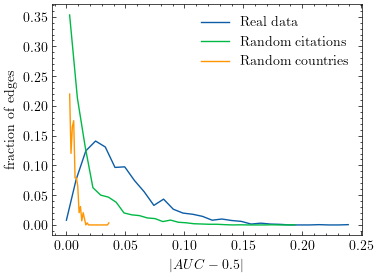

In [13]:
randc_dist, rc_auc_bin = np.histogram(np.abs(rand_country_cumulative_net['AUC'].values - 0.5), bins=30)

real_dist,  auc_bin= np.histogram(np.abs(cumulative_net['AUC'].values - 0.5), bins=30)

randnet_dist, rn_auc_bin = np.histogram(np.abs(rand_cumulative_net['AUC'].values - 0.5), bins=30)


fig, ax = plt.subplots(1,1,figsize=(4,3))

ax.plot(auc_bin[:-1], real_dist/real_dist.sum(), label='Real data')

ax.plot(rn_auc_bin[:-1], randnet_dist/randnet_dist.sum(), label='Random citations')

ax.plot(rc_auc_bin[:-1], randc_dist/randc_dist.sum(), label='Random countries')

ax.set_xlabel("$| AUC - 0.5 |$")
ax.set_ylabel("fraction of edges")
plt.legend()
plt.savefig(os.path.join(path2figures, 'FigSI_random_network_auc_dist2.pdf'))

plt.show()

In [14]:
cumulative_net

,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
13234,AM,1990.0,JP,0.464545,0.000030,52,-6.473036,4.802651e-11,True
13476,TR,1990.0,SE,0.451030,0.000122,68,-4.438116,4.537489e-06,True
12805,FR,1990.0,CL,0.359139,0.000331,52,-7.746956,4.706063e-15,True
13071,PH,1990.0,GB,0.459976,0.000076,153,-4.593378,2.180643e-06,True
13776,CZ,1991.0,CA,0.457302,0.000071,237,-5.077888,1.908265e-07,True
...,...,...,...,...,...,...,...,...,...
116770,KR,2017.0,FR,0.485110,0.000004,15119,-7.162995,3.946658e-13,True
116764,JP,2017.0,FR,0.515543,0.000003,21850,8.525760,7.590469e-18,True
116761,IT,2017.0,FR,0.528478,0.000003,28624,17.413197,3.276039e-68,True
116894,DE,2017.0,GB,0.537599,0.000001,62822,32.991880,5.310210e-239,True


In [15]:
rand_country_cumulative_net

,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
228,ZM,2017.0,AR,0.494022,3.796714e-07,50,-9.701195,1.489933e-22,True
7037,BH,2017.0,PL,0.492773,5.719681e-07,96,-9.555375,6.156837e-22,True
6690,PA,2017.0,NZ,0.491732,4.125156e-07,54,-12.873382,3.177870e-38,True
6682,MO,2017.0,NZ,0.484846,4.116413e-07,74,-23.619440,1.216783e-123,True
6632,BO,2017.0,NZ,0.489646,4.906490e-07,51,-14.781886,9.586091e-50,True
...,...,...,...,...,...,...,...,...,...
3924,CA,2017.0,ID,0.510808,4.849269e-06,13773,4.907812,4.604914e-07,True
3917,BI,2017.0,ID,0.496598,4.422906e-07,78,-5.115787,1.562176e-07,True
3673,IS,2017.0,HK,0.487617,3.967116e-07,64,-19.660844,2.334453e-86,True
2706,MD,2017.0,EG,0.492815,4.171090e-07,56,-11.124932,4.743935e-29,True


In [16]:
rand_cumulative_net

,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
18119,NG,1990,JP,0.493910,0.000002,85,-4.609406,2.019105e-06,True
18142,GB,1990,KE,0.381832,0.000283,67,-7.027879,1.048480e-12,True
18056,ES,1990,IT,0.469173,0.000025,801,-6.216192,2.546820e-10,True
18057,FI,1990,IT,0.473816,0.000024,401,-5.391738,3.488969e-08,True
18069,MA,1990,IT,0.491288,0.000001,51,-7.747810,4.674557e-15,True
...,...,...,...,...,...,...,...,...,...
132231,IN,2017,HK,0.564537,0.000011,6513,19.241390,8.333849e-83,True
132228,ID,2017,HK,0.544847,0.000015,3904,11.462358,1.019432e-30,True
132225,GR,2017,HK,0.525017,0.000027,1374,4.853030,6.079475e-07,True
132221,FR,2017,HK,0.555652,0.000014,4601,14.729005,2.099220e-49,True


## Source Data for Supplementary Figure 18

The plotted values of the |AUC - 0.5| distributions (`FigSI_random_network_auc_dist2.pdf`), written to `Source Data/SourceData_FigS18.xlsx`.

In [17]:
# the Source Data helpers (sourcedatautils.py, in the code folder like vizutils.py)
from sourcedatautils import write_source_data

title = 'Supplementary Figure 18: Null-model validation of citation-preference discrimination.'
description = ('Citation preferences (AUC) of the empirical country citation network and of two null models. Each network is '
               'the cumulative network of 1990-2017 (pairs with N >= 50 cited publications, Holm-Sidak correction with '
               'alpha = 0.01 within each year, significant edges only, the latest year of each country pair). Random '
               'Citations: the cited publications are shuffled among the citations with the same citing and cited '
               'publication years. Random Countries: the country of each publication is shuffled among the publications '
               'of the same year (2017 publications); the target country is compared with all cited publications. '
               'Distributions: fraction of edges in each of 30 equal-width bins of |AUC - 0.5|, plotted at the lower edge '
               'of the bin; the bins of each network span the values of that network.')

distributions = pd.concat([
    pd.DataFrame({'Network':name, 'Bin lower edge':bins[:-1], 'Bin upper edge':bins[1:],
                  'Edges':dist, 'Fraction of edges':dist/dist.sum()})
    for name, bins, dist in [('Empirical', auc_bin, real_dist),
                             ('Random citations', rn_auc_bin, randnet_dist),
                             ('Random countries', rc_auc_bin, randc_dist)]], ignore_index=True)

tables = [('Distributions', 'Plotted values of FigSI_random_network_auc_dist2.pdf: fraction of edges in each bin of |AUC - 0.5|.', distributions)]

write_source_data('SourceData_FigS18.xlsx', title, description, tables)

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS18.xlsx


wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
